# 02 — EDA & Fraud Patterns

## Task 1: Data Audit

**Objective:** Assess the dataset's structure, completeness, consistency, duplicates, feature types, and target distribution before exploratory analysis or modelling.

**Dataset:** Vehicle Insurance Claim Fraud Detection (`fraud_oracle.csv`)

### Audit checklist
1. Load the dataset
2. Inspect dimensions and sample records
3. Review column names and data types
4. Check missing values
5. Check duplicate rows
6. Inspect categorical cardinality and numeric summaries
7. Examine the target distribution and class imbalance
8. Identify potential data-quality concerns and modelling cautions
9. Export audit summaries

> **Important:** This audit does not remove records or transform features. We are documenting the data first; cleaning decisions will be made after reviewing evidence.

## 1. Imports and configuration

This cell imports the libraries and finds the raw CSV whether the notebook is launched from the project root or from the `notebooks/` folder.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Find project root from common notebook working directories
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in candidates if (p / 'data' / 'raw' / 'fraud_oracle.csv').exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Could not locate data/raw/fraud_oracle.csv. '
        'Run this notebook from the project root or notebooks folder.'
    )

DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'fraud_oracle.csv'
REPORTS_DIR = PROJECT_ROOT / 'reports'
REPORTS_DIR.mkdir(exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Dataset path:', DATA_PATH)

Project root: c:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection
Dataset path: c:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\data\raw\fraud_oracle.csv


## 2. Load the dataset

We load the raw dataset and preserve it as `df`. No changes are made at this stage.

In [2]:
df = pd.read_csv(DATA_PATH)

print('Dataset loaded successfully.')
print(f'Rows: {df.shape[0]:,}')
print(f'Columns: {df.shape[1]:,}')
print(f'Total cells: {df.shape[0] * df.shape[1]:,}')

Dataset loaded successfully.
Rows: 15,420
Columns: 33
Total cells: 508,860


## 3. First look at the records

Review the first and last rows to check whether values look as expected and whether any obvious formatting issues are visible.

In [3]:
display(df.head())
display(df.tail())

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
15415,Nov,4,Friday,Toyota,Urban,Tuesday,Nov,5,Male,Married,...,6 years,31 to 35,No,No,External,none,no change,1 vehicle,1996,Collision
15416,Nov,5,Thursday,Pontiac,Urban,Friday,Dec,1,Male,Married,...,6 years,31 to 35,No,No,External,more than 5,no change,3 to 4,1996,Liability
15417,Nov,5,Thursday,Toyota,Rural,Friday,Dec,1,Male,Single,...,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision
15418,Dec,1,Monday,Toyota,Urban,Thursday,Dec,2,Female,Married,...,2 years,31 to 35,No,No,External,more than 5,no change,1 vehicle,1996,All Perils
15419,Dec,2,Wednesday,Toyota,Urban,Thursday,Dec,3,Male,Single,...,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision


## 4. Dataset dimensions and column names

Confirm the shape and inspect every feature name. We will later map each field to its business meaning.

In [4]:
print('Shape:', df.shape)
print('\nColumn names:')
for i, col in enumerate(df.columns, start=1):
    print(f'{i:02d}. {col}')

Shape: (15420, 33)

Column names:
01. Month
02. WeekOfMonth
03. DayOfWeek
04. Make
05. AccidentArea
06. DayOfWeekClaimed
07. MonthClaimed
08. WeekOfMonthClaimed
09. Sex
10. MaritalStatus
11. Age
12. Fault
13. PolicyType
14. VehicleCategory
15. VehiclePrice
16. FraudFound_P
17. PolicyNumber
18. RepNumber
19. Deductible
20. DriverRating
21. Days_Policy_Accident
22. Days_Policy_Claim
23. PastNumberOfClaims
24. AgeOfVehicle
25. AgeOfPolicyHolder
26. PoliceReportFiled
27. WitnessPresent
28. AgentType
29. NumberOfSuppliments
30. AddressChange_Claim
31. NumberOfCars
32. Year
33. BasePolicy


## 5. Data types and structural information

The data type is not necessarily the same as the business meaning. For example, a numeric-coded category may be stored as an integer. We will use this output to decide which columns need special handling later.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Month                 15420 non-null  str  
 1   WeekOfMonth           15420 non-null  int64
 2   DayOfWeek             15420 non-null  str  
 3   Make                  15420 non-null  str  
 4   AccidentArea          15420 non-null  str  
 5   DayOfWeekClaimed      15420 non-null  str  
 6   MonthClaimed          15420 non-null  str  
 7   WeekOfMonthClaimed    15420 non-null  int64
 8   Sex                   15420 non-null  str  
 9   MaritalStatus         15420 non-null  str  
 10  Age                   15420 non-null  int64
 11  Fault                 15420 non-null  str  
 12  PolicyType            15420 non-null  str  
 13  VehicleCategory       15420 non-null  str  
 14  VehiclePrice          15420 non-null  str  
 15  FraudFound_P          15420 non-null  int64
 16  PolicyNumber   

In [6]:
dtype_summary = (
    df.dtypes.astype(str)
      .value_counts()
      .rename_axis('data_type')
      .reset_index(name='column_count')
)
display(dtype_summary)

,data_type,column_count
0,str,24
1,int64,9


## 6. Missing-value audit

Check missing values by column and calculate the percentage of missing data. A zero missing-value count does not rule out placeholder values such as `Unknown`, `-`, or empty strings; we will inspect those separately.

In [7]:
missing_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
    'non_missing_count': df.notna().sum()
}).sort_values('missing_count', ascending=False)

display(missing_summary)

print('Total missing cells:', int(df.isna().sum().sum()))
print('Columns with missing values:', int((df.isna().sum() > 0).sum()))

,missing_count,missing_percent,non_missing_count
Month,0,0.0,15420
WeekOfMonth,0,0.0,15420
DayOfWeek,0,0.0,15420
Make,0,0.0,15420
AccidentArea,0,0.0,15420
DayOfWeekClaimed,0,0.0,15420
MonthClaimed,0,0.0,15420
WeekOfMonthClaimed,0,0.0,15420
Sex,0,0.0,15420
MaritalStatus,0,0.0,15420


Total missing cells: 0
Columns with missing values: 0


## 7. Duplicate-record audit

Check fully duplicated rows. We will not delete duplicates automatically—first we need to understand whether duplicates represent accidental repetition or legitimate repeated claim/policy information.

In [8]:
duplicate_count = int(df.duplicated().sum())
duplicate_percent = round(duplicate_count / len(df) * 100, 2) if len(df) else 0

print(f'Fully duplicated rows: {duplicate_count:,}')
print(f'Duplicate percentage: {duplicate_percent}%')

if duplicate_count:
    display(df[df.duplicated(keep=False)].head(20))

Fully duplicated rows: 0
Duplicate percentage: 0.0%


## 8. Numeric-column summary

Summarize numeric columns using descriptive statistics. Remember: integer columns may represent categories, counts, or encoded labels rather than continuous measurements.

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print('Numeric columns:', len(numeric_cols))
display(df[numeric_cols].describe().T)

Numeric columns: 9


,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.00,3.0,4.00,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.00,3.0,4.00,5.0
Age,15420.0,39.855707,13.492377,0.0,31.00,38.0,48.00,80.0
FraudFound_P,15420.0,0.059857,0.237230,0.0,0.00,0.0,0.00,1.0
PolicyNumber,15420.0,7710.500000,4451.514911,1.0,3855.75,7710.5,11565.25,15420.0
RepNumber,15420.0,8.483268,4.599948,1.0,5.00,8.0,12.00,16.0
Deductible,15420.0,407.704280,43.950998,300.0,400.00,400.0,400.00,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.00,2.0,3.00,4.0
Year,15420.0,1994.866472,0.803313,1994.0,1994.00,1995.0,1996.00,1996.0


## 9. Categorical-column cardinality

Inspect the number of unique values in categorical columns. High-cardinality features may need special attention; low-cardinality columns may be categorical even if stored numerically.

In [10]:
categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

cardinality_summary = pd.DataFrame({
    'unique_values': df[categorical_cols].nunique(dropna=False),
    'top_value': [df[col].mode(dropna=False).iloc[0] if not df[col].mode(dropna=False).empty else np.nan
                  for col in categorical_cols],
    'top_value_frequency': [df[col].value_counts(dropna=False).iloc[0] if not df[col].empty else 0
                             for col in categorical_cols]
}, index=categorical_cols).sort_values('unique_values', ascending=False)

display(cardinality_summary)

C:\Users\rudra\AppData\Local\Temp\ipykernel_8828\2761331443.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


,unique_values,top_value,top_value_frequency
Make,19,Pontiac,3837
MonthClaimed,13,Jan,1446
Month,12,Jan,1411
PolicyType,9,Sedan - Collision,5584
AgeOfPolicyHolder,9,31 to 35,5593
AgeOfVehicle,8,7 years,5807
DayOfWeekClaimed,8,Monday,3757
DayOfWeek,7,Monday,2616
VehiclePrice,6,20000 to 29000,8079
AddressChange_Claim,5,no change,14324


## 10. Inspect categorical values

This creates a compact value listing for categorical columns. If any column has too many unique values, only the first 30 values are shown. Look for inconsistent spelling, whitespace, unexpected categories, or placeholder values.

In [11]:
for col in categorical_cols:
    print(f'\n### {col} ({df[col].nunique(dropna=False)} unique values)')
    values = df[col].value_counts(dropna=False).head(30)
    display(values.to_frame('frequency'))


### Month (12 unique values)


,frequency
Month,
Jan,1411
May,1367
Mar,1360
Jun,1321
Oct,1305
Dec,1285
Apr,1280
Feb,1266
Jul,1257



### DayOfWeek (7 unique values)


,frequency
DayOfWeek,
Monday,2616
Friday,2445
Tuesday,2300
Thursday,2173
Wednesday,2159
Saturday,1982
Sunday,1745



### Make (19 unique values)


,frequency
Make,
Pontiac,3837
Toyota,3121
Honda,2801
Mazda,2354
Chevrolet,1681
Accura,472
Ford,450
VW,283
Dodge,109


... (38 outputs left out)


### NumberOfCars (5 unique values)


,frequency
NumberOfCars,
1 vehicle,14316
2 vehicles,709
3 to 4,372
5 to 8,21
more than 8,2



### BasePolicy (3 unique values)


,frequency
BasePolicy,
Collision,5962
Liability,5009
All Perils,4449


## 11. Target-variable audit

Our target is `FraudFound_P`. Verify that the target exists, inspect its labels, and calculate the class distribution. The positive class should represent fraud; confirm this from the dataset's coding and documentation before modelling.

In [12]:
TARGET = 'FraudFound_P'

if TARGET not in df.columns:
    raise KeyError(f'Target column {TARGET!r} not found. Check the column list above.')

target_counts = df[TARGET].value_counts(dropna=False).rename('count').to_frame()
target_counts['percentage'] = (target_counts['count'] / len(df) * 100).round(2)
display(target_counts)

print('Target labels:', df[TARGET].unique())
print('Target missing values:', int(df[TARGET].isna().sum()))

,count,percentage
FraudFound_P,,
0,14497,94.01
1,923,5.99


Target labels: [0 1]
Target missing values: 0


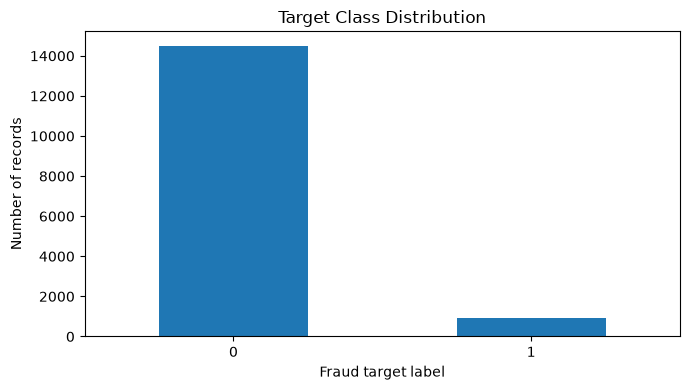

In [13]:
# Plot target distribution
import matplotlib.pyplot as plt

ax = df[TARGET].value_counts(dropna=False).plot(kind='bar', figsize=(7, 4))
ax.set_title('Target Class Distribution')
ax.set_xlabel('Fraud target label')
ax.set_ylabel('Number of records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Baseline class-imbalance calculation

Calculate the fraud prevalence and the expected number of fraud cases under random selection of 200 claims. This provides a simple operational baseline for later comparison with our ranked model.

In [14]:
# Adjust mapping only if the target labels are different from the expected coding
fraud_label = 1
legitimate_label = 0

fraud_count = int((df[TARGET] == fraud_label).sum())
legitimate_count = int((df[TARGET] == legitimate_label).sum())
fraud_rate = fraud_count / len(df)

INVESTIGATION_CAPACITY = 200
expected_fraud_random_200 = INVESTIGATION_CAPACITY * fraud_rate

print(f'Total claims: {len(df):,}')
print(f'Fraud claims: {fraud_count:,}')
print(f'Legitimate claims: {legitimate_count:,}')
print(f'Fraud prevalence: {fraud_rate:.2%}')
print(f'Random-selection expected fraud among {INVESTIGATION_CAPACITY}: {expected_fraud_random_200:.1f}')
print(f'Random-selection expected Recall@{INVESTIGATION_CAPACITY}: {INVESTIGATION_CAPACITY / len(df):.2%}')

Total claims: 15,420
Fraud claims: 923
Legitimate claims: 14,497
Fraud prevalence: 5.99%
Random-selection expected fraud among 200: 12.0
Random-selection expected Recall@200: 1.30%


## 13. Potential data-quality flags

This section identifies possible placeholder-like values in text fields. These are only flags for review, not automatic cleaning rules.

In [15]:
placeholder_tokens = {'unknown', 'unk', 'n/a', 'na', 'none', 'null', '-', '?', 'not available', 'missing'}

placeholder_summary = []
for col in categorical_cols:
    normalized = df[col].astype('string').str.strip().str.lower()
    count = int(normalized.isin(placeholder_tokens).sum())
    if count > 0:
        placeholder_summary.append({
            'column': col,
            'placeholder_count': count,
            'placeholder_percent': round(count / len(df) * 100, 2),
            'placeholder_values': sorted(normalized[normalized.isin(placeholder_tokens)].dropna().unique().tolist())
        })

placeholder_df = pd.DataFrame(placeholder_summary)
if placeholder_df.empty:
    print('No exact placeholder tokens from the predefined list were found.')
else:
    display(placeholder_df.sort_values('placeholder_count', ascending=False))

,column,placeholder_count,placeholder_percent,placeholder_values
3,NumberOfSuppliments,7047,45.70,[none]
2,PastNumberOfClaims,4352,28.22,[none]
0,Days_Policy_Accident,55,0.36,[none]
1,Days_Policy_Claim,1,0.01,[none]


## 14. Audit summary

Create a concise summary table of the major audit findings. Review it and add your business interpretation in the markdown cell below.

In [16]:
audit_summary = pd.DataFrame({
    'audit_item': [
        'Rows', 'Columns', 'Total cells', 'Missing cells', 'Columns with missing values',
        'Fully duplicated rows', 'Numeric columns', 'Categorical columns',
        'Fraud cases', 'Legitimate cases', 'Fraud prevalence (%)'
    ],
    'result': [
        df.shape[0], df.shape[1], df.shape[0] * df.shape[1],
        int(df.isna().sum().sum()), int((df.isna().sum() > 0).sum()),
        duplicate_count, len(numeric_cols), len(categorical_cols),
        fraud_count, legitimate_count, round(fraud_rate * 100, 2)
    ]
})
display(audit_summary)

,audit_item,result
0,Rows,15420.00
1,Columns,33.00
2,Total cells,508860.00
3,Missing cells,0.00
4,Columns with missing values,0.00
5,Fully duplicated rows,0.00
6,Numeric columns,9.00
7,Categorical columns,24.00
8,Fraud cases,923.00
9,Legitimate cases,14497.00


## 15. Export audit outputs

Save the summary tables to `reports/` so our findings are reproducible and can be used in the project report.

In [17]:
audit_summary.to_csv(REPORTS_DIR / 'data_audit_summary.csv', index=False)
missing_summary.to_csv(REPORTS_DIR / 'missing_values_audit.csv')
dtype_summary.to_csv(REPORTS_DIR / 'dtype_summary.csv', index=False)
cardinality_summary.to_csv(REPORTS_DIR / 'categorical_cardinality.csv')
target_counts.to_csv(REPORTS_DIR / 'target_distribution.csv')

if not placeholder_df.empty:
    placeholder_df.to_csv(REPORTS_DIR / 'placeholder_values_audit.csv', index=False)

print('Audit reports saved to:', REPORTS_DIR)

Audit reports saved to: c:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports
